# El dataset de MNIST

In [3]:
import tensorflow as tf
tf.compat.v1.disable_eager_execution()
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

In [4]:
x_train, x_test = x_train / 255.0, x_test / 255.0

In [5]:
len(x_train)

60000

In [6]:
len(x_test)

10000

In [7]:
im_temp = x_train[0]

In [8]:
# Convierte las etiquetas a formato One-Hot (por ejemplo, de 0 a 9 clases)
y_train_onehot = tf.keras.utils.to_categorical(y_train, num_classes=10)
y_test_onehot = tf.keras.utils.to_categorical(y_test, num_classes=10)

In [10]:
from skimage import io
import numpy as np

C:\Users\progr\AppData\Local\Temp\ipykernel_3740\3721667675.py:1: FutureWarning: `imshow` is deprecated since version 0.25 and will be removed in version 0.27. Please use `matplotlib`, `napari`, etc. to visualize images.
  io.imshow(np.reshape(im_temp, [28,28]))


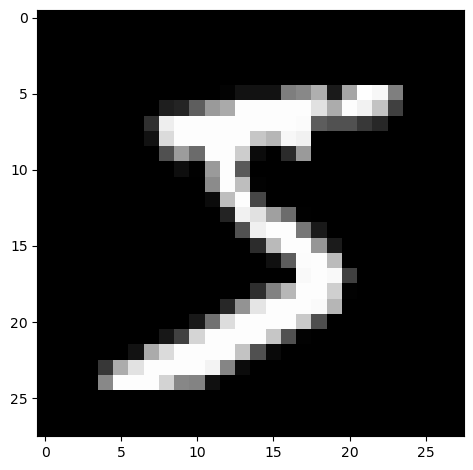

In [11]:
io.imshow(np.reshape(im_temp, [28,28]))

In [12]:
print("Etiqueta:", y_train[0])

Etiqueta: 5


# Una red neuronal con Tensor Flow - v1
* Las imagenes de entrenamiento con MNIST viven en un espacio vectorial de dimension 784.
* El data se puede pensar como 60000 filas y 784 columnas.
* Cada dato del dataset es un numero real entre 0 y 1.

y = softmax(W * x + b)

In [22]:
# 1. Arquitectura y placeholders
dim_input = 784
n_categories = 10

In [14]:
x = tf.compat.v1.placeholder(tf.float32, [None, dim_input])
y_ = tf.compat.v1.placeholder(tf.float32, [None, n_categories])

In [15]:
W = tf.Variable(tf.zeros([dim_input, n_categories]))
b = tf.Variable(tf.zeros([n_categories]))

In [16]:
softmax_args = tf.matmul(x, W) + b
y_hat = tf.nn.softmax(softmax_args)

#### Entrenando la red neuronal
* Loss / Cost <- Objetivo: Minimizar las perdidas

In [29]:
from IPython.display import display, Math, Latex

In [36]:
display(Math(r"H_{y'}(\hat{y}) = -\sum_{i} y_i log(\hat{y_i})"))

<IPython.core.display.Math object>

In [17]:
# 2. Pérdida y optimizador (Asegúrate de que train_step use la nueva pérdida)
cross_entropy = tf.reduce_mean(
    tf.compat.v1.nn.softmax_cross_entropy_with_logits(
        labels=y_, logits=softmax_args
    )
)

Instructions for updating:

Future major versions of TensorFlow will allow gradients to flow
into the labels input on backprop by default.

See `tf.nn.softmax_cross_entropy_with_logits_v2`.



In [18]:
train_step = tf.compat.v1.train.GradientDescentOptimizer(0.5).minimize(
    cross_entropy
)

In [19]:
# 3. Sesión e inicialización
session = tf.compat.v1.InteractiveSession()
tf.compat.v1.global_variables_initializer().run()

In [23]:
# 4. Bucle de entrenamiento
import numpy as np

for _ in range(100000):
  batch_idx = np.random.choice(len(x_train), 150)
  batch_x = x_train[batch_idx].reshape(-1, 784)
  batch_y = y_train_onehot[batch_idx]

  session.run(train_step, feed_dict={x: batch_x, y_: batch_y})

#### Evaluando la red neuronal

In [24]:
# 5. Evaluación final
correct_predictions = tf.equal(tf.argmax(y_hat, 1), tf.argmax(y_, 1))
accuracy = tf.reduce_mean(tf.cast(correct_predictions, tf.float32))

x_test_flat = x_test.reshape(-1, 784)
print(
    session.run(
        accuracy, feed_dict={x: x_test_flat, y_: y_test_onehot}
    )
)

0.9235
